In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [8]:
# (x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# print(x_train.shape)
# print(x_test.shape)

# x_train = x_train / 255.0
# x_test = x_test / 255.0
train = pd.read_csv("HandWritten MNIST/mnist_train.csv")
test = pd.read_csv("HandWritten MNIST/mnist_test.csv")

x_train = train.drop('label', axis=1).values
y_train = train['label'].values

x_test = test.drop('label', axis=1).values
y_test = test['label'].values

# Normalize pixel values
x_train = x_train / 255.0
x_test = x_test / 255.0

In [11]:
model = keras.Sequential([
    layers.Flatten(input_shape=(784, )),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
    optimizer=keras.optimizers.SGD(),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train, y_train,
    epochs=11,
    validation_data=(x_test, y_test)
)

Epoch 1/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 18s 9ms/step - accuracy: 0.8234 - loss: 0.6483 - val_accuracy: 0.9092 - val_loss: 0.3211
Epoch 2/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9164 - loss: 0.2959 - val_accuracy: 0.9251 - val_loss: 0.2585
Epoch 3/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9298 - loss: 0.2435 - val_accuracy: 0.9358 - val_loss: 0.2195
Epoch 4/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9395 - loss: 0.2092 - val_accuracy: 0.9442 - val_loss: 0.1914
Epoch 5/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9467 - loss: 0.1831 - val_accuracy: 0.9476 - val_loss: 0.1745
Epoch 6/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9540 - loss: 0.1622 - val_accuracy: 0.9534 - val_loss: 0.1551
Epoch 7/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.9582 - loss: 0.1458 - val_accuracy: 0.9575 - val_loss: 0.1389
Epoch 8/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.9623 - loss: 0

In [13]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9669 - loss: 0.1088
Test Loss: 0.10883656144142151
Test Accuracy: 0.9668999910354614


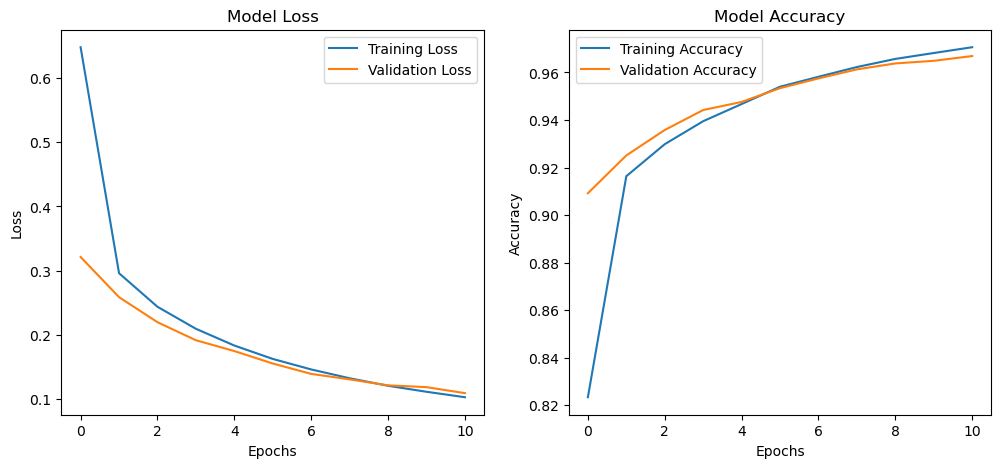

In [17]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()